<div style="background-color:#B5121B;color:#ffffff;padding:16px 22px;border-radius:6px;font-family:Arial, Helvetica, sans-serif;">
<div style="font-size:12px;letter-spacing:0.08em;text-transform:uppercase;opacity:0.85;">PHYS7101 &middot; Numerical Methods and Data Analysis</div>
<div style="font-size:21px;font-weight:700;margin-top:6px;line-height:1.3;">Week 2 — Fitting Models: What Sets the Tide?</div>
</div>

<div style="background-color:#38614A;color:#ffffff;padding:10px 16px;border-radius:4px;font-family:Arial, Helvetica, sans-serif;font-weight:700;margin-top:10px;">
Worked solutions: try each exercise yourself first, then compare.
</div>

#### Fit a tidal model to the Lancaster Quay record from Week 1: test the procedure on generated data, fit with the period fixed and then free, find out what the model is missing, and judge the result.
***

## Where this fits

In Week 1 you looked at a week of water levels from Lancaster Quay. The peaks were about 12.3 hours apart, close to the 12.42-hour M2 lunar tide, and the distribution was strongly skewed. Lecture 3 then showed that fitting a model means **minimising χ²**, that a model can be *linear in its parameters* even when it describes an oscillation, and that a fit is only finished once you have judged it: residuals, χ²/ν, uncertainties and correlations.

Today you fit a tidal model to that record, following the lecture's workflow:

1. test the fitting procedure on generated data with known answers;
2. fit the real record with the tidal period fixed (a linear fit);
3. let the period float (a nonlinear fit) and see what it finds;
4. work out what is missing from the model, and judge the final fit.

The figure you will make repeatedly (data and model on top, residuals underneath) is covered in detail in `week2_code_and_plots.ipynb`.

## <span style="color:#B5121B">0. Load the data (provided)</span>

766 readings over 191.5 hours


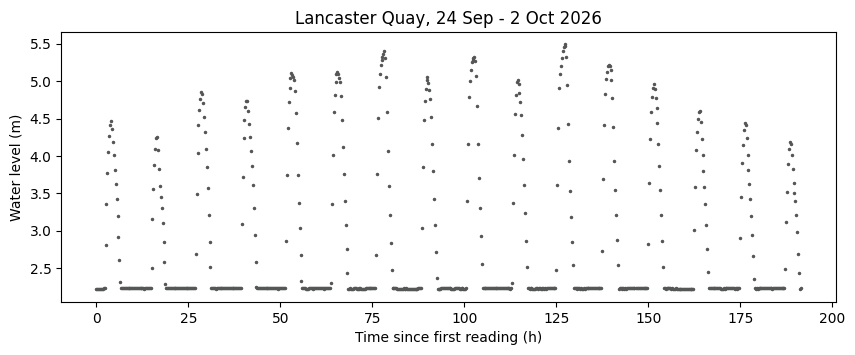

In [1]:
import os

# Data: read from a local datasets/ folder if you've cloned/downloaded the
# repository, otherwise straight from GitHub (e.g. in Colab). Same file either way.
DATA_URL = "https://raw.githubusercontent.com/MatSmithAstro/phys7101_2026_resources/main/workshops/week2/datasets/"

def data_path(filename):
    local = os.path.join("datasets", filename)
    return local if os.path.exists(local) else DATA_URL + filename

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

tide = pd.read_csv(data_path("lancaster_quay_tidal.csv"))
tide["time"] = pd.to_datetime(tide["time"])

# Time in hours since the first reading, and the level in metres
t = (tide["time"] - tide["time"].iloc[0]).dt.total_seconds().to_numpy() / 3600
level = tide["level_m"].to_numpy()
print(f"{len(t)} readings over {t[-1]:.1f} hours")

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(t, level, ".", ms=3, color="#555656")
ax.set_xlabel("Time since first reading (h)")
ax.set_ylabel("Water level (m)")
ax.set_title("Lancaster Quay, 24 Sep - 2 Oct 2026")
plt.show()

## <span style="color:#B5121B">1. The model</span>

The simplest tide is one sinusoid of period $P$:

$$h(t) = c + a\cos\omega t + b\sin\omega t, \qquad \omega = \frac{2\pi}{P}.$$

The amplitude is $A = \sqrt{a^2 + b^2}$. Written this way, with $P$ known, the model is **linear in its parameters** $(c, a, b)$, even though it oscillates (Lecture 3, slide 18). Each extra frequency adds one more cosine and sine column, and the model stays linear as long as every period is fixed.

For a linear model, build the **design matrix**: one column per parameter, each evaluated at every time, divided by $\sigma$ (slide 17):

$$A = \frac{1}{\sigma}\begin{pmatrix} 1 & \cos\omega_1 t_1 & \sin\omega_1 t_1 & \cos\omega_2 t_1 & \dots \\ \vdots & & & & \end{pmatrix}, \qquad \mathbf{b} = \mathbf{y}/\sigma,$$

then solve $A\boldsymbol{\theta} \approx \mathbf{b}$ with `np.linalg.lstsq`. The covariance of the parameters is $C = (A^TA)^{-1}$.

Write three functions:

* `chi2(y, y_model, sigma)`: $\chi^2 = \sum_i \left[(y_i - f_i)/\sigma_i\right]^2$ (Lecture 3, slide 15). You will use it for every fit today. (Store results in a variable such as `chi2_val`, not `chi2`, or you will overwrite the function.)
* `design_matrix(t, periods)`: a column of ones, then a cosine and a sine column for each period in the list;
* `linear_fit(t, y, sigma, periods)`: returns the parameters, their covariance matrix, χ² (from your `chi2`) and the degrees of freedom ν = N − p.

In [2]:
def chi2(y, y_model, sigma):
    """Chi-squared of data y against model values y_model, with uncertainties sigma."""
    return np.sum(((y - y_model) / sigma) ** 2)

def design_matrix(t, periods):
    """Columns: 1, then cos(2 pi t / P) and sin(2 pi t / P) for each period P."""
    columns = [np.ones_like(t)]
    for P in periods:
        w = 2 * np.pi / P
        columns += [np.cos(w * t), np.sin(w * t)]
    return np.column_stack(columns)

def linear_fit(t, y, sigma, periods):
    """Weighted linear least squares. Returns (theta, cov, chi2_value, nu)."""
    X = design_matrix(t, periods)
    A = X / sigma if np.ndim(sigma) == 0 else X / sigma[:, None]
    b = y / sigma
    theta = np.linalg.lstsq(A, b, rcond=None)[0]
    cov = np.linalg.inv(A.T @ A)
    chi2_value = chi2(y, X @ theta, sigma)
    nu = len(y) - len(theta)
    return theta, cov, chi2_value, nu

<details><summary><b>Stuck? Open a hint</b> (try for 10 minutes first)</summary>

* `chi2`: one line with `np.sum`.
* `design_matrix`: start a list with `np.ones_like(t)`, append a cosine and a sine column for each period, then `np.column_stack` the list.
* `linear_fit`: divide the design matrix and the data by $\sigma$, solve with `np.linalg.lstsq(A, b, rcond=None)[0]`, and get the covariance from $(A^TA)^{-1}$ with `np.linalg.inv`. Compute χ² from the *undivided* design matrix times θ. ν is the number of points minus the number of parameters.

</details>

## <span style="color:#B5121B">2. Test on generated data first</span>

Before fitting real data, check that the procedure recovers known answers (Lecture 3, Part D). The cell below makes a fake tide at the same times as the real one: $c = 2.8$ m, $a = 0.6$ m, $b = 0.8$ m, $P = 12.4206$ h (M2), plus Gaussian noise with $\sigma = 0.05$ m.

In [3]:
M2 = 12.4206            # M2 lunar semi-diurnal period, hours
true = {"c": 2.8, "a": 0.6, "b": 0.8}
sigma_fake = 0.05       # m

rng = np.random.default_rng(1)
def make_fake_tide():
    return (true["c"] + true["a"] * np.cos(2 * np.pi * t / M2)
            + true["b"] * np.sin(2 * np.pi * t / M2) + rng.normal(0, sigma_fake, t.size))

fake = make_fake_tide()

Fit `fake` with `linear_fit` (period M2). Print each parameter with its uncertainty next to the true value, and χ²/ν. Are the true values within about 1σ? Is χ²/ν close to 1, within $\pm\sqrt{2/\nu}$?

In [4]:
theta, cov, chi2_val, nu = linear_fit(t, fake, sigma_fake, [M2])
errors = np.sqrt(np.diag(cov))
for name, value, err in zip(["c", "a", "b"], theta, errors):
    print(f"{name}: true {true[name]:.3f}   fitted {value:.4f} ± {err:.4f}   "
          f"({(value - true[name]) / err:+.1f} sigma)")
print(f"chi2/nu = {chi2_val / nu:.3f}  (expect 1 ± {np.sqrt(2 / nu):.3f})")

c: true 2.800   fitted 2.7970 ± 0.0018   (-1.7 sigma)
a: true 0.600   fitted 0.5976 ± 0.0026   (-0.9 sigma)
b: true 0.800   fitted 0.7989 ± 0.0026   (-0.4 sigma)
chi2/nu = 0.951  (expect 1 ± 0.051)


### <span style="color:#FD9029">Optional: is one success luck?</span>

One success could be luck. Repeat the fake experiment 500 times and histogram the **pull** of $a$, $z = (\hat a - a_\text{true})/\sigma_{\hat a}$. If the fit is unbiased and its error bars are honest, the pulls have mean 0 and standard deviation 1 (lecture slide 29).

pull mean -0.022, std 1.046, |z| < 1 for 69%


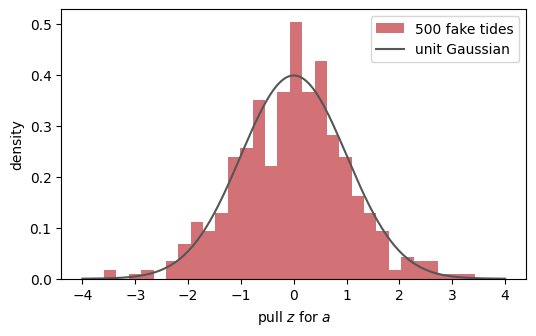

In [5]:
pulls = []
for _ in range(500):
    theta_i, cov_i, _, _ = linear_fit(t, make_fake_tide(), sigma_fake, [M2])
    pulls.append((theta_i[1] - true["a"]) / np.sqrt(cov_i[1, 1]))
pulls = np.array(pulls)
print(f"pull mean {pulls.mean():+.3f}, std {pulls.std():.3f}, |z| < 1 for {np.mean(np.abs(pulls) < 1):.0%}")

z = np.linspace(-4, 4, 200)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(pulls, bins=30, density=True, color="#B5121B", alpha=0.6, label="500 fake tides")
ax.plot(z, np.exp(-z**2 / 2) / np.sqrt(2 * np.pi), color="#555656", label="unit Gaussian")
ax.set_xlabel("pull $z$ for $a$")
ax.set_ylabel("density")
ax.legend()
plt.show()

<span style="color:#38614A">**Answer.**</span> $a$ and $b$ land within 1σ of the truth and $c$ is 1.7σ low (a 1-in-11 event, so not alarming on its own); χ²/ν ≈ 0.95 (within $1 \pm 0.05$). The pulls have mean ≈ 0 and standard deviation ≈ 1.0, with about 68% inside ±1: the fit is unbiased and its error bars are honest. Only now is it worth applying the procedure to real data.

## <span style="color:#B5121B">3. Fit the real record with the period fixed</span>

We need $\sigma$ for the real readings. On the low-water plateau (Week 1) the water barely moves, so the scatter there estimates the gauge noise:

In [6]:
plateau = level < 2.24
sigma_gauge = level[plateau].std()
print(f"{plateau.sum()} plateau readings, scatter {sigma_gauge * 1000:.1f} mm")
sigma_real = 0.004   # m: rounded up, and used below

491 plateau readings, scatter 3.6 mm


Fit three models, all linear with fixed periods:

1. M2 only: `[M2]`;
2. M2 and its first two harmonics: `[M2, M2/2, M2/3]` (the tide here isn't symmetric, Week 1);
3. as (2) plus `M2/4`.

For each, print the number of parameters, the rms of the residuals and χ²/ν. Then plot the data with model (2) on top and the residuals in units of σ underneath.

M2                : p =  3, rms residual 0.662 m, chi2/nu = 27,494
M2 + 2 harmonics  : p =  7, rms residual 0.462 m, chi2/nu = 13,452
M2 + 3 harmonics  : p =  9, rms residual 0.461 m, chi2/nu = 13,433


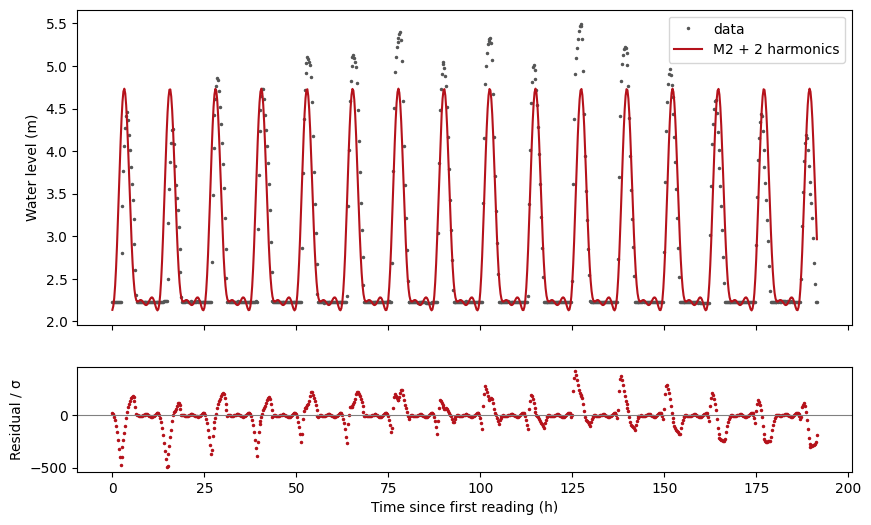

In [7]:
models = {"M2": [M2],
          "M2 + 2 harmonics": [M2, M2 / 2, M2 / 3],
          "M2 + 3 harmonics": [M2, M2 / 2, M2 / 3, M2 / 4]}
for name, periods in models.items():
    theta, cov, chi2_val, nu = linear_fit(t, level, sigma_real, periods)
    resid = level - design_matrix(t, periods) @ theta
    print(f"{name:18s}: p = {len(theta):2d}, rms residual {resid.std():.3f} m, chi2/nu = {chi2_val / nu:,.0f}")

periods = models["M2 + 2 harmonics"]
theta, cov, chi2_val, nu = linear_fit(t, level, sigma_real, periods)
model = design_matrix(t, periods) @ theta

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True,
                               gridspec_kw={"height_ratios": [3, 1]})
ax1.plot(t, level, ".", ms=3, color="#555656", label="data")
ax1.plot(t, model, color="#B5121B", label="M2 + 2 harmonics")
ax1.set_ylabel("Water level (m)")
ax1.legend(loc="upper right")
ax2.plot(t, (level - model) / sigma_real, ".", ms=3, color="#B5121B")
ax2.axhline(0, color="grey", lw=0.8)
ax2.set_xlabel("Time since first reading (h)")
ax2.set_ylabel("Residual / σ")
plt.show()

<span style="color:#38614A">**Answer.**</span> rms residual: 0.66 m (M2 only), 0.46 m (with two harmonics), 0.46 m (three). Adding harmonics helps once, then stops helping. χ²/ν is in the tens of thousands: the residuals are ~100σ, not ~1σ. They are not noise. Two patterns stand out: the model's peaks are the same every day, but the observed high tides grow to ~5.5 m mid-week and fall back again (the range changes over the 8 days, which a fixed-amplitude model cannot do); and the model drifts out of step with the data over the week, so the residuals on the rising and falling tides swap sign. The harmonics do reproduce the shape of each tide, including much of the low-water plateau.

## <span style="color:#B5121B">4. Let the period float: a nonlinear fit</span>

Perhaps 12.42 h is the wrong period for this record. If $P$ is a free parameter the model is no longer linear in its parameters, so we need `scipy.optimize.curve_fit` (Levenberg–Marquardt, slide 19), which needs a starting guess `p0`.

The function `tide_model` below takes the parameters as `(c, a1, b1, a2, b2, ..., P)`, with harmonics $k\omega$ for $k = 1, 2, \dots$. Fit it with three harmonics (8 parameters), `sigma=np.full_like(level, sigma_real)` and `absolute_sigma=True`, starting from $P_0$ = 12, 13, 11 and 6 hours (amplitudes start at 0.5, 0.5 then zeros; $c$ at 2.8).

* Which starting values give the same answer? What do the others find, and how does their χ²/ν compare?
* For the best fit, how far is $P$ from 12.42 h, in units of its uncertainty? Repeat with `absolute_sigma=False`, which rescales the errors by $\sqrt{\chi^2/\nu}$. Does that change your conclusion?

In [8]:
from scipy.optimize import curve_fit

def tide_model(t, *p):
    """c + sum_k [a_k cos(k w t) + b_k sin(k w t)], w = 2 pi / P; p = (c, a1, b1, ..., P)."""
    c, P = p[0], p[-1]
    w = 2 * np.pi / P
    out = np.full_like(t, c, dtype=float)
    n_harm = (len(p) - 2) // 2
    for k in range(1, n_harm + 1):
        out += p[2 * k - 1] * np.cos(k * w * t) + p[2 * k] * np.sin(k * w * t)
    return out

<details><summary><b>Stuck? Open a hint</b> (try for 10 minutes first)</summary>

The starting list has 8 entries, $(c, a_1, b_1, a_2, b_2, a_3, b_3, P)$, so `p0 = [2.8, 0.5, 0.5, 0, 0, 0, 0, P0]`. With 8 parameters `curve_fit` may need more than its default number of function evaluations: look up its `maxfev` argument. The period's uncertainty is the square root of the last diagonal element of the covariance matrix.

</details>

In [9]:
results = {}
for P0 in [12, 13, 11, 6]:
    p0 = [2.8, 0.5, 0.5, 0, 0, 0, 0, P0]
    p, C = curve_fit(tide_model, t, level, p0=p0, sigma=np.full_like(level, sigma_real),
                     absolute_sigma=True, maxfev=50000)
    chi2_nu = chi2(level, tide_model(t, *p), sigma_real) / (len(level) - len(p))
    results[P0] = (p, C, chi2_nu)
    print(f"P0 = {P0:2d} h -> P = {p[-1]:.4f} ± {np.sqrt(C[-1, -1]):.5f} h, chi2/nu = {chi2_nu:,.0f}")

p, C, chi2nu = results[12]
P_fit, P_err = p[-1], np.sqrt(C[-1, -1])
P_err_scaled = P_err * np.sqrt(chi2nu)
print(f"\nBest fit P = {P_fit:.4f} h; M2 = {M2} h")
print(f"  absolute_sigma=True : ±{P_err:.5f} h -> {(M2 - P_fit) / P_err:,.0f} sigma from M2")
print(f"  rescaled by sqrt(chi2/nu): ±{P_err_scaled:.4f} h -> {(M2 - P_fit) / P_err_scaled:.0f} sigma from M2")

P0 = 12 h -> P = 12.3009 ± 0.00004 h, chi2/nu = 5,256
P0 = 13 h -> P = 12.3009 ± 0.00004 h, chi2/nu = 5,256
P0 = 11 h -> P = 11.1616 ± 0.00043 h, chi2/nu = 62,139
P0 =  6 h -> P = 6.1510 ± 0.00003 h, chi2/nu = 44,892

Best fit P = 12.3009 h; M2 = 12.4206 h
  absolute_sigma=True : ±0.00004 h -> 2,848 sigma from M2
  rescaled by sqrt(chi2/nu): ±0.0030 h -> 39 sigma from M2


<span style="color:#38614A">**Answer.**</span> From $P_0$ = 12 or 13 h the fit converges to $P = 12.30$ h with χ²/ν ≈ 5,000 (much better than the fixed-M2 fits). From 11 h it stops at a **local minimum** near 11.2 h (χ²/ν ≈ 60,000), and from 6 h it locks onto the second harmonic, 6.15 h. Same data, same model, different answers: the starting guess matters (Lecture 3, slides 12 and 19).
The best period is 12.30 h, about 0.12 h short of M2. With `absolute_sigma=True` the quoted error (~0.00004 h) puts it thousands of σ away; even rescaled by $\sqrt{\chi^2/\nu}$ (±0.003 h) it is ~40σ away. A tiny statistical error is not the same as a correct answer: when χ²/ν ≫ 1 the model is missing something, and the error bars mean very little.

## <span style="color:#FD9029">5. Optional: why the starting guess matters, χ² against the period</span>

*Optional in the lab: a good one to come back to, and a possible route for the Exercise 1 extension.*

With the period fixed, the fit is linear and takes a fraction of a second. So we can map the whole χ² landscape that `curve_fit` was exploring: fit the three-harmonic model, `[P, P/2, P/3]`, at 2000 periods between 5 and 26 h, and record χ² each time.

1. Plot χ²/ν against $P$ (log $y$ axis) and mark where your four `curve_fit` runs ended. Why did they end up in different places?
2. Zoom in: scan ±0.0003 h around the best period with 601 points and plot $\chi^2 - \chi^2_\text{min}$. The 1σ range of $P$ is where this stays below 1 (Lecture 3, slide 24). Compare half its width with the uncertainty `curve_fit` gave.

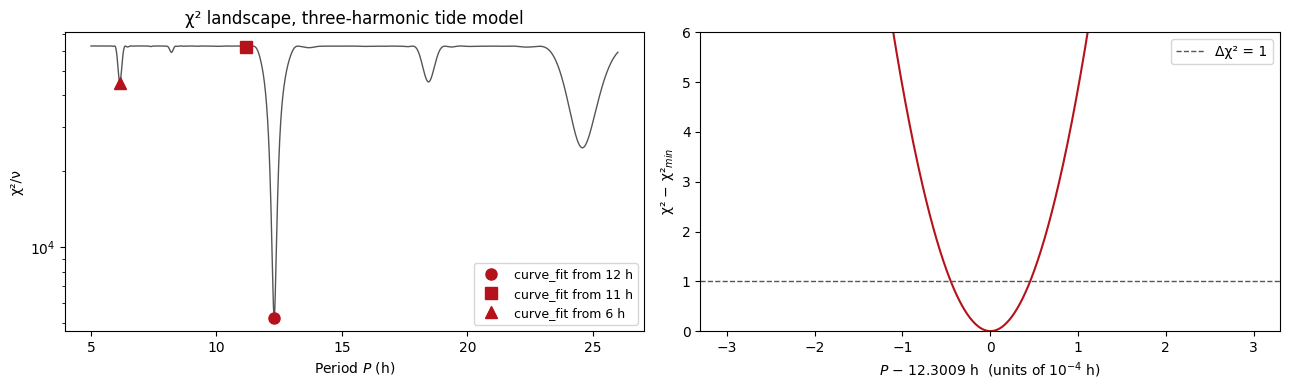

lowest chi2 on the coarse grid at P = 12.301 h
Delta chi2 = 1 half-width: 0.000044 h; curve_fit (absolute_sigma): 0.000042 h


In [10]:
P_grid = np.linspace(5, 26, 2000)
nu_scan = len(level) - 8
chi2_grid = np.array([linear_fit(t, level, sigma_real, [P, P / 2, P / 3])[2] for P in P_grid])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
ax1.semilogy(P_grid, chi2_grid / nu_scan, color="#555656", lw=1)
for P0, marker in [(12, "o"), (11, "s"), (6, "^")]:
    p, C, chi2_nu = results[P0]
    ax1.plot(p[-1], chi2_nu, marker, color="#B5121B", ms=8, label=f"curve_fit from {P0} h")
ax1.legend(fontsize=9, loc="lower right")
ax1.set_xlabel("Period $P$ (h)")
ax1.set_ylabel("χ²/ν")
ax1.set_title("χ² landscape, three-harmonic tide model")

P_best = P_grid[np.argmin(chi2_grid)]
P_centre = results[12][0][-1]
P_fine = np.linspace(P_centre - 0.0003, P_centre + 0.0003, 601)
chi2_fine = np.array([linear_fit(t, level, sigma_real, [P, P / 2, P / 3])[2] for P in P_fine])
delta = chi2_fine - chi2_fine.min()
inside = P_fine[delta < 1]
half_width = (inside.max() - inside.min()) / 2

ax2.plot((P_fine - P_centre) * 1e4, delta, color="#B5121B")
ax2.axhline(1, color="#555656", ls="--", lw=1, label="Δχ² = 1")
ax2.set_ylim(0, 6)
ax2.set_xlabel(f"$P$ − {P_centre:.4f} h  (units of $10^{{-4}}$ h)")
ax2.set_ylabel("χ² − χ²$_{min}$")
ax2.legend()
plt.tight_layout()
plt.show()

print(f"lowest chi2 on the coarse grid at P = {P_best:.3f} h")
print(f"Delta chi2 = 1 half-width: {half_width:.6f} h; curve_fit (absolute_sigma): {np.sqrt(results[12][1][-1, -1]):.6f} h")

<span style="color:#38614A">**Answer.**</span> The landscape is mostly a flat plateau at χ²/ν ≈ 62,000: for a period far from the real one, the sinusoids average out over 8 days and fit nothing. It has one deep, narrow minimum at 12.30 h, plus shallower dips where one of the model's harmonics lines up with the real tide (6.15 h, 18.4 h and 24.6 h, i.e. 12.30 h × ½, 3/2 and 2). `curve_fit` is a local method: it follows the slope downhill from where it starts. From 12 or 13 h it falls into the global minimum; from 6 h it finds the 6.15 h dip; from 11 h it is on the flat plateau, where χ² barely changes with $P$, so it stops almost where it started. This is the optimisation half of Lecture 3 in one picture: fitting *is* minimising χ², with all the problems of slide 12. Scanning χ² against the parameter (or trying several starting points) is a cheap way to find the global minimum.
Near the minimum χ² is a parabola, and Δχ² = 1 gives a half-width of 4.4 × 10⁻⁵ h, the same as `curve_fit`'s 4.2 × 10⁻⁵ h: `curve_fit`'s error *is* the curvature of χ². Both are equally meaningless here, because χ²/ν ≈ 5,000 (Section 4).

## <span style="color:#B5121B">6. What's missing? A second tide</span>

The Sun raises a tide too: the **S2** solar semi-diurnal tide, period exactly 12.00 h. M2 and S2 drift in and out of step every

$$\left(\frac{1}{12.00} - \frac{1}{12.42}\right)^{-1} \approx 355\ \text{h} \approx 14.8\ \text{days},$$

producing **spring tides** (in step, large range) and **neap tides** (out of step, small range). Over our 8 days, the sum looks like a single tide with a period between 12.00 and 12.42 h and a changing amplitude, which is what the free-period fit found.

With both periods fixed the model is linear again. The cell below fits `[M2, S2, M2/2, M2/3, S2/2, MS4]` with your `linear_fit` (`MS4 = 1 / (1/M2 + 1/S2)` is the compound tide from the two together). Run it and compare the rms residual and χ²/ν with the free-period fit of Section 4.

In [11]:
S2 = 12.0
MS4 = 1 / (1 / M2 + 1 / S2)
periods_ms = [M2, S2, M2 / 2, M2 / 3, S2 / 2, MS4]
try:
    theta, cov, chi2_val, nu = linear_fit(t, level, sigma_real, periods_ms)
    model_ms = design_matrix(t, periods_ms) @ theta
    print(f"M2 + S2 model: p = {len(theta)}, rms residual {(level - model_ms).std():.3f} m, chi2/nu = {chi2_val / nu:,.0f}")
    print(f"M2 amplitude {np.hypot(theta[1], theta[2]):.2f} m, S2 amplitude {np.hypot(theta[3], theta[4]):.2f} m")
except NotImplementedError:
    print("Not implemented yet: complete the functions above, then re-run this cell.")

M2 + S2 model: p = 13, rms residual 0.287 m, chi2/nu = 5,227
M2 amplitude 0.82 m, S2 amplitude 0.40 m


### <span style="color:#FD9029">Optional: correlated parameters</span>

Print the correlation matrix of the four main M2 and S2 coefficients (`theta[1:5]`), $\rho_{jk} = C_{jk}/\sqrt{C_{jj}C_{kk}}$. Why are some of them correlated, and what would reduce the correlation?

In [12]:
sub = cov[1:5, 1:5]
corr = sub / np.sqrt(np.outer(np.diag(sub), np.diag(sub)))
print("\ncorrelations of (M2 cos, M2 sin, S2 cos, S2 sin):")
print(np.round(corr, 2))


correlations of (M2 cos, M2 sin, S2 cos, S2 sin):
[[ 1.   -0.01  0.07 -0.59]
 [-0.01  1.    0.57  0.08]
 [ 0.07  0.57  1.    0.  ]
 [-0.59  0.08  0.    1.  ]]


<span style="color:#38614A">**Answer.**</span> The fixed M2 + S2 model reaches rms 0.29 m and χ²/ν ≈ 5,000, as good as the free-period fit, but now every parameter has a physical meaning (M2 amplitude ≈ 0.82 m, S2 ≈ 0.40 m). Some M2 and S2 coefficients are correlated (ρ ≈ −0.6 between the M2 cosine and S2 sine terms, +0.6 between the M2 sine and S2 cosine terms): 8 days is about half the 14.8-day beat period, so the record cannot cleanly separate the two tides, and a little more of one can be traded for a little less of the other. A record of at least one full spring–neap cycle (about 15 days, better several) would reduce the correlation: the classic tidal-analysis rule is to observe for longer than $1/\Delta f$ for the frequencies you want to separate.

## <span style="color:#B5121B">7. Judge the final fit</span>

χ²/ν is still in the thousands. Following the lecture's checklist, look at the residuals before blaming the noise:

1. plot the data and the M2 + S2 model for the first 48 hours;
2. plot the residual against the water level (`plt.plot(level, level - model_ms, ".")`).

Where does the model fail? Look back at the Week 1 histogram. Why would it be wrong to "fix" χ²/ν by increasing σ until it equals 1 (slide 22)?

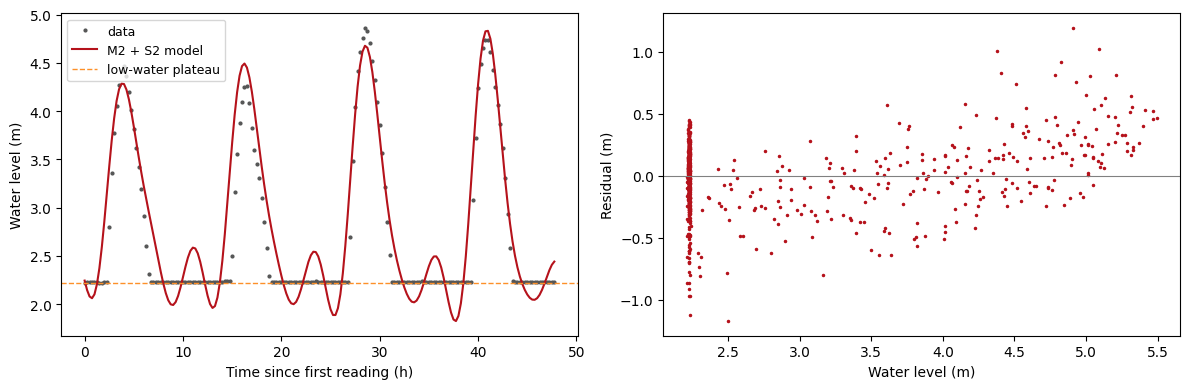

lowest model value 1.79 m; mean residual above 4.5 m: +0.28 m


In [13]:
first = t < 48
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(t[first], level[first], ".", ms=4, color="#555656", label="data")
ax1.plot(t[first], model_ms[first], color="#B5121B", label="M2 + S2 model")
ax1.axhline(2.22, color="#FD9029", ls="--", lw=1, label="low-water plateau")
ax1.set_xlabel("Time since first reading (h)")
ax1.set_ylabel("Water level (m)")
ax1.legend(fontsize=9)
ax2.plot(level, level - model_ms, ".", ms=3, color="#B5121B")
ax2.axhline(0, color="grey", lw=0.8)
ax2.set_xlabel("Water level (m)")
ax2.set_ylabel("Residual (m)")
plt.tight_layout()
plt.show()
print(f"lowest model value {model_ms.min():.2f} m; mean residual above 4.5 m: {(level - model_ms)[level > 4.5].mean():+.2f} m")

<span style="color:#38614A">**Answer.**</span> The model fails in exactly the places Week 1 pointed to. At low water it wiggles between ~1.8 and ~2.6 m, while the river sits on its ~2.22 m plateau (the largest residuals in the right-hand plot are at that level); at high water it can't reach the sharp, narrow peaks (on average ~0.3 m too low above 4.5 m). A sum of a few sinusoids is smooth and symmetric about its mean; this record is clipped at the bottom and peaked at the top. Increasing σ would make χ²/ν ≈ 1 and inflate every error bar, but it would turn real, deterministic behaviour (the river's low-water floor) into fake "noise", exactly the mistake on slide 22. The honest conclusion: the M2 + S2 model captures the timing of the tides well; its amplitudes are only rough, and the record needs a model of the river's floor (or a fit to high water only) before the uncertainties mean anything.

## The verdict

In your logbook:

1. Why test on generated data first? What would you have missed without the pulls?
2. Which of your fits were linear and which nonlinear, and why does that matter in practice?
3. The free-period fit gave $P$ = 12.30 h with a tiny error bar. What was wrong with that answer, and how did the residuals tell you?
4. What would you need (data or model) to measure the M2 and S2 amplitudes properly?

## <span style="color:#FD9029">Extension (optional, unassessed): UK graduate earnings</span>

A different kind of data. `graduate_earnings.csv` (from the UK government's graduate labour-market statistics) gives median salaries from 2007 to 2020 with uncertainties, split by `gender` and `graduate_type`.

1. Select `gender == "all"` and `graduate_type == "graduate"`. Fit a straight line with `curve_fit`, using `sigma=income_err` and `absolute_sigma=True`. What is χ²/ν? Now plot the residuals. Do the two tell the same story?
2. Fit quadratic and cubic models (`np.polyfit` with `w=1/income_err` works). What happens to χ²/ν, and why is a very small χ²/ν suspicious (slide 23)?
3. Fit the straight line using `year` directly, then `year - 2007`. Compare the correlation between intercept and slope (slide 24).
4. These are *nominal* salaries. What else would you want to know before saying that graduate earnings rose?

line: 22440 + 359 per year, chi2/nu = 1.04
normalised residuals: [ 0.8  0.8  0.7  0.2  0.2 -0.1 -0.5 -1.3 -1.  -1.6 -0.9 -0.8  0.3  1.9]
degree 2: chi2/nu = 0.32
degree 3: chi2/nu = 0.03
x = year        : corr(intercept, slope) = -1.0000
x = year - 2007 : corr(intercept, slope) = -0.8669


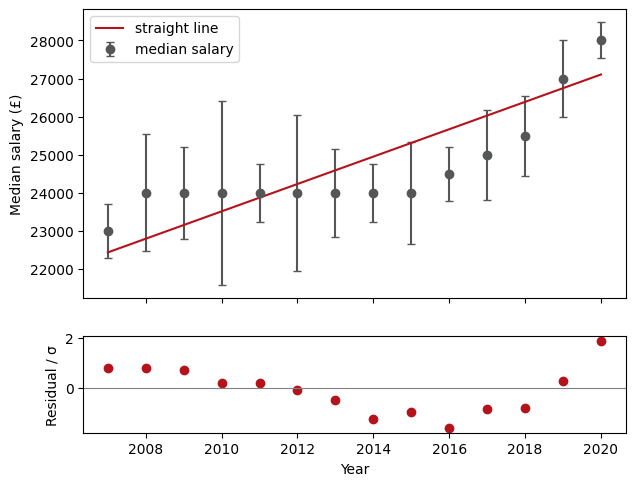

In [14]:
earnings = pd.read_csv(data_path("graduate_earnings.csv"))
sel = earnings[(earnings["gender"] == "all") & (earnings["graduate_type"] == "graduate")]
year, income, err = sel["year"].to_numpy(), sel["income"].to_numpy(), sel["income_err"].to_numpy()

line = lambda x, a, b: a + b * x
x = year - 2007
p, C = curve_fit(line, x, income, sigma=err, absolute_sigma=True)
resid = (income - line(x, *p)) / err
print(f"line: {p[0]:.0f} + {p[1]:.0f} per year, chi2/nu = {np.sum(resid**2) / (len(x) - 2):.2f}")
print("normalised residuals:", np.round(resid, 1))

for deg in [2, 3]:
    coef = np.polyfit(x, income, deg, w=1 / err)
    r = (income - np.polyval(coef, x)) / err
    print(f"degree {deg}: chi2/nu = {np.sum(r**2) / (len(x) - deg - 1):.2f}")

for label, xx in [("year", year), ("year - 2007", x)]:
    _, Cx = curve_fit(line, xx, income, sigma=err, absolute_sigma=True)
    print(f"x = {label:12s}: corr(intercept, slope) = {Cx[0, 1] / np.sqrt(Cx[0, 0] * Cx[1, 1]):+.4f}")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(7, 5.5), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
ax1.errorbar(year, income, yerr=err, fmt="o", color="#555656", capsize=3, label="median salary")
ax1.plot(year, line(x, *p), color="#B5121B", label="straight line")
ax1.set_ylabel("Median salary (£)")
ax1.legend()
ax2.plot(year, resid, "o", color="#B5121B")
ax2.axhline(0, color="grey", lw=0.8)
ax2.set_xlabel("Year")
ax2.set_ylabel("Residual / σ")
plt.show()

<span style="color:#38614A">**Answer.**</span> 1. The straight line gives χ²/ν ≈ 1.0, which looks fine, but the residuals are clearly structured: positive at both ends and negative in the middle (flat until ~2015, then rising). The numbers alone would have passed a wrong model; the residual plot does not (Lecture 3, slide 21, and Anscombe).
2. Quadratic χ²/ν ≈ 0.3, cubic ≈ 0.03. Values far below 1 mean either the uncertainties are overestimated or the model is fitting the noise. With 14 points and these error bars, a cubic is overfitting. The quoted uncertainties are also worth questioning: where do they come from?
3. Using `year` directly, the intercept is the salary in year 0 and is almost perfectly anti-correlated with the slope (ρ ≈ −1.00); centring on 2007 gives ρ ≈ −0.87, and centring on the mean year would make it ≈ 0.
4. Inflation: in real terms, flat nominal salaries from 2008 to 2015 were a fall. Also the changing size and mix of the graduate population, and how the medians and their uncertainties were computed.

<hr style="border:none;border-top:1px solid #BEC0C2;margin-top:32px;">
<div style="color:#555656;font-size:12px;margin-top:8px;font-family:Arial, Helvetica, sans-serif;">
PHYS7101 &mdash; Numerical Methods and Data Analysis
</div>